|                |   |
:----------------|---|
| **Nombre**     |  David Farias Rivera |
| **Fecha**      |  08/10/2026 |
| **Expediente** | 754381  | 

In [42]:
axi.imshow?

Signature:
axi.imshow(
    X,
    cmap=None,
    norm=None,
    *,
    aspect=None,
    interpolation=None,
    alpha=None,
    vmin=None,
    vmax=None,
    colorizer=None,
    origin=None,
    extent=None,
    interpolation_stage=None,
    filternorm=True,
    filterrad=4.0,
    resample=None,
    url=None,
    data=None,
    **kwargs,
)
Docstring:
Display data as an image, i.e., on a 2D regular raster.

The input may either be actual RGB(A) data, or 2D scalar data, which
will be rendered as a pseudocolor image. For displaying a grayscale
image, set up the colormapping using the parameters
``cmap='gray', vmin=0, vmax=255``.

The number of pixels used to render an image is set by the Axes size
and the figure *dpi*. This can lead to aliasing artifacts when
the image is resampled, because the displayed image size will usually
not match the size of *X* (see
:doc:`/gallery/images_contours_and_fields/image_antialiasing`).
The resampling can be controlled via the *interpolation* parameter
a

Necesitamos diseñar un sistema capaz de identificar las caras de varias personas a travez de un kernel 


In [43]:
from sklearn.datasets import fetch_lfw_people   # Descargamos la libreria para descargar el dataset de caras
faces = fetch_lfw_people(min_faces_per_person=60) # Importamos el dataset de caras, con un minimo de 60 caras por persona
print(faces.target_names) # Imprimimos los nombres de las personas que descargamos de el dataset 
print(faces.images.shape) # 

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
(1348, 62, 47)


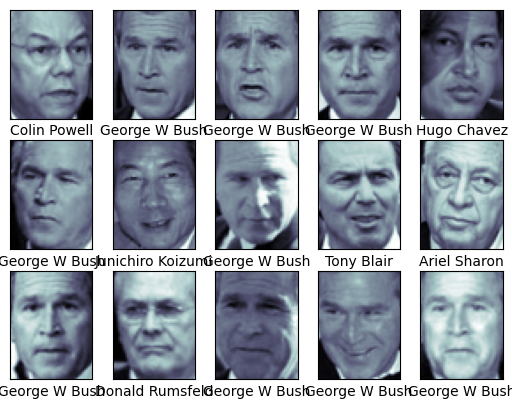

In [44]:
import matplotlib.pyplot as plt
%matplotlib inline 

fig, ax = plt.subplots(3, 5) # creamos una figura con 3 filas y 5 columnas
for i, axi in enumerate(ax.flat): #
    axi.imshow(faces.images[i], cmap='bone') #Aqui usamos imshow para transformar el texto a las imagenes 
    axi.set(xticks=[], yticks=[], #Aqui usamos set para configurar las etiquetas de los ejes
            xlabel=faces.target_names[faces.target[i]]) #Aqui usamos xlabel para mostrar el nombre de la persona en la imagen

Randomized PCA sirve para eliminar columnas y variables que no aporten mucho a la varianza de nuestro resultado, tomamlos las 150 columnas mas relevantes para la varianza y las hacemos planco y negro para que pesen mucho menos 

Necesitamos reducir y optimizar las dimensiones de el Data Set para nuestro modelo de ML, descartando ruido y variables con una alta covarianza, 
Utiliza RandomizedPCA realizar estos ajustes y tambien la creacion de el propio modelo que vamos a usar un RBF para esta ocasion 


In [45]:

from sklearn.svm import SVC 
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42) 
svc = SVC(kernel='rbf', class_weight='balanced') #Definimos el modelo de SVC con kernel rbf y balanceamos las clases
model = make_pipeline(pca, svc) # Definimos el modelo como un pipeline que primero aplica PCA y luego SVC

Usa train_test_split para dividir nuestro data set de las caras de manera correcta entre el Train y el test de nuestra eje X que son nuestras caras y el Y los nombres de las personas en el dataset

In [46]:
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42) # Atribuimos los datos de entrenamiento y prueba, con un random_state para reproducibilidad

Necesitamos encontrar los parametros de Busqueda con el MODELO que tenemos para diferentes valores de C y gamma 

In [47]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50], # Definimos los parametros de busqueda para el modelo SVC, con diferentes valores de C y gamma
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid) # Definimos la busqueda de hiperparametros

%time grid.fit(Xtrain, ytrain) # Ejecutamos la busqueda de hiperparametros
print(grid.best_params_) # Imprimimos los mejores parametros encontrados

CPU times: user 1min 20s, sys: 1min 12s, total: 2min 33s
Wall time: 9.28 s
{'svc__C': 5, 'svc__gamma': 0.001}


In [48]:
model = grid.best_estimator_ # Definimos el modelo como el mejor estimador encontrado
yfit = model.predict(Xtest) # Realizamos las predicciones sobre los datos de prueba

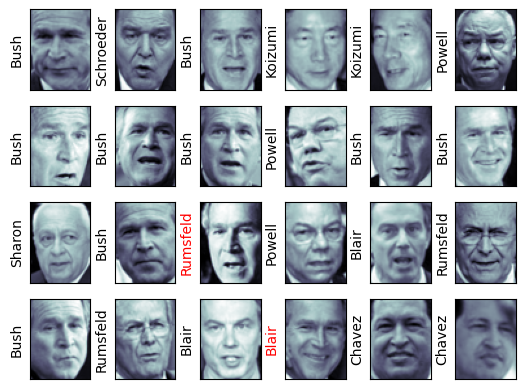

In [49]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')

Creamos un reporte de clasificacion en donde se nos diga que porcetaje de aciertos tuvimos en nuestro TEST 


In [50]:

from sklearn.metrics import classification_report 
print(classification_report(ytest, yfit,
                            target_names=faces.target_names)) # Creamos un reporte de clasificacion para evaluar el rendimiento del modelo, mostrando precision, recall y f1-score para cada clase

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Creamos una matriz de confusion para reporesentar nuestra Y test y train para ver como nos fue 

<Axes: >

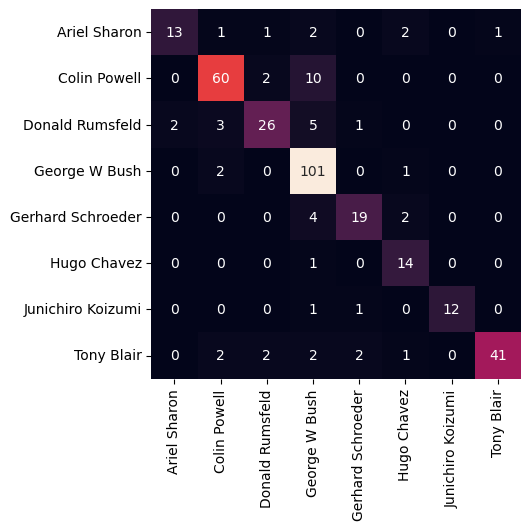

In [51]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)

In [52]:
from sklearn import datasets
digits = datasets.load_digits()
print(digits.target_names)
print(digits.images.shape)
print(digits.data.shape)    # Cada imagen convertida en 64 valores

[0 1 2 3 4 5 6 7 8 9]
(1797, 8, 8)
(1797, 64)


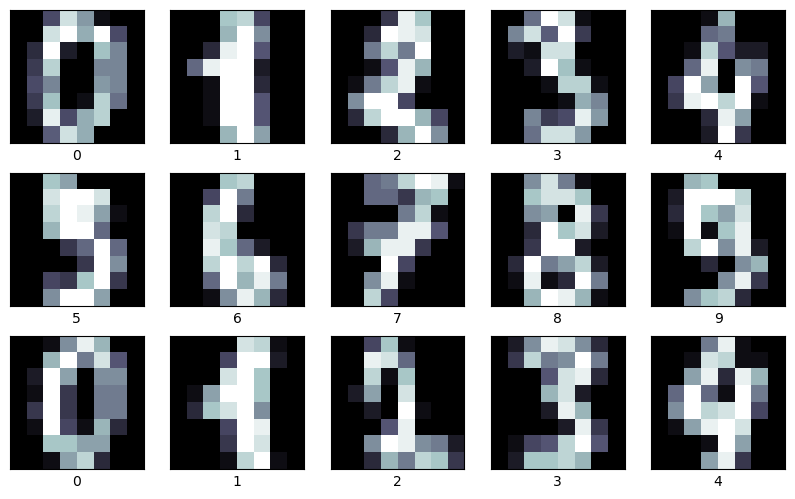

In [53]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(3, 5, figsize=(10, 6))

for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='bone')
    axi.set(
    xticks=[], yticks=[],
    xlabel=str(digits.target[i])
    )

plt.show()

In [54]:


pca_2 = RandomizedPCA(n_components=30, whiten=True, random_state=42)
svc_2 = SVC(kernel='rbf', class_weight='balanced')

modelo_2 = make_pipeline(pca_2, svc_2)

In [55]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(digits.data,digits.target,random_state=42)

In [56]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.005, 0.01, 0.05, 0.1]
}

grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)

print(grid.best_params_)
print(grid.best_score_)

CPU times: user 57.3 ms, sys: 8.27 ms, total: 65.5 ms
Wall time: 68.4 ms


ValueError: 
All the 80 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
80 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/pipeline.py", line 655, in fit
    Xt = self._fit(X, y, routed_params, raw_params=params)
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/pipeline.py", line 589, in _fit
    X, fitted_transformer = fit_transform_

In [ ]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

In [ ]:
fig, ax = plt.subplots(4, 6, figsize=(10, 8))

for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(8, 8), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(
        str(yfit[i]),
        color='black' if yfit[i] == ytest[i] else 'red'
    )

plt.tight_layout()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    ytest,
    yfit,
    target_names=[str(n) for n in digits.target_names]
))

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(ytest, yfit)

sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=digits.target_names,
    yticklabels=digits.target_names
)

plt.xlabel('Dígito real')
plt.ylabel('Dígito predicho')
plt.show()

## References

1. Scikit-learn developers. (n.d.). sklearn.datasets.fetch_lfw_people. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_lfw_people.html#sklearn.datasets.fetch_lfw_people

2. Scikit-learn developers. (n.d.). SVM kernels. Scikit-learn. https://scikit-learn.org/stable/modules/svm.html#svm-kernels

3. Scikit-learn developers. (n.d.). sklearn.svm.SVC. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

4. Scikit-learn developers. (n.d.). sklearn.decomposition.PCA. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA